Guide d'analyse IMU tibiale => objectif ecriture et compréhension du scrip

La question centre : Une mousse ferme (B) augmente-t-elle les impacts au niveua du tibai par rapport à une mousse (A), cela depend t'il du terrain, comment les coureurs le percoivent 

Plan de l'analyse
1) Contrôler (fichier, pla, fréquence)
2) Réparer (si il manque des données comment je m'en occupe)
3) Filtrer mes données / signals => utilisation Butterworth
4) Détection des pics d'impact / de contact / et décollement
5) Mesurer => PTA / taux de charge / contact / cadence 
6) Nettoyer => rejet des foulées à > 3 MAD 
7) Agréger => 1 moyenne par essai 
8) Tester => t apparié, dz, modèle mixte, SPM
9) Corrélation intra-sujet
10) Validation


Partie 1 : importation de l'ensemble des bibliothèques dont je vais avoir besoin pour effectuer mon analyse 

In [ ]:
import json 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks, welch
from scipy import stats as sps
import statsmodels.formula.api as smf
from statsmodels.stats.power import TTestPower
%pip install spm1d

plt.rcParams["figure.figsize"] = (10,4)
plt.rcParams["axes.grid"] = True
print("Tout est readyyyy")

Note: you may need to restart the kernel to use updated packages.
Tout est readyyyy


Partie 2 - Les réglages, ce bout de code rassemble tous les paramètres dans un seul dictionnaire => CONFIG

In [ ]:
# Partie 2 => Réglages de l'études
CONFIG = {
    "dossier": Path("donnes_etude"),    # là où sereont écrites les données 
    "fs" : 500,    # fréquence d'échantillonage (Hz)
    "etendue_g" : 16,     # étendue de la mesure de l'accéléromètre (± 16g => au dessus = saturation
    "chaussures": ["A", "B"], 
    "pentes" : ["plat", "descente"],

    # traitement
    "fc_acc": 60,    # coupure du filtre pour l'accélération (Hz)
    "fc_gyr": 30,   # coupure pour le gyroscope (Hz)
    "trou_max_s" : 0.10,   # trous plus courts : interpolés ; plus longs = ingorés
    "seuil_pic_g" : 3.0,    # Hauteur minimal d'un impact 
    "distance_pics_s":0.5,  # écart minimal entre deux impacts du même pied
    "n_mad": 3.0,       # rejet des foulées à plus de 3 MAD de la médiane

    # Qualité 
    "duree_min_s": 15, 
    "nan_max" : 0.05,       # au dela de 5% de valeurs manquantes 
}
FS = CONFIG["fs"]
IMU = CONFIG["dossier"] / "imu"





Parite 3 = Fabrication des données par Claude pour pouvoir m'entrainer sur le déroulé d'une étude 

simuler_essai : une foulée = somme de formes simples 
Mettre le schéma








In [ ]:
def gauss(t, mu, sd):
    return np.exp(-0.5 * ((t - mu) / sd) ** 2)

def simuler_essai(pta, t_contact, cadence, t_montee, rng, fs=500, duree=20.0, etendue=16.0):
    '''Simule un essai IMU tibial. Renvoie (tableau, vérité).'''
    t = np.arange(0, duree, 1 / fs)
    acc = np.ones_like(t) + 0.05 * np.sin(2 * np.pi * 0.1 * t + rng.uniform(0, 6))   # gravité
    ap, gyr = np.zeros_like(t), np.zeros_like(t)
    T = 120.0 / cadence                                   # durée d'une foulée (2 pas)
    tfs = rng.uniform(0.3, 0.6)                           # premier contact
    verite = {"t_fs": [], "pta": []}
    while tfs < duree - 0.2:
        p = pta * rng.normal(1, 0.08)                     # variabilité foulée à foulée
        ct = t_contact + rng.normal(0, 0.008)
        r = t_montee * rng.normal(1, 0.08)
        A, tau = p - 1.0, t - tfs
        m1 = (tau >= 0) & (tau < r)
        acc[m1] += A * np.sin(np.pi / 2 * tau[m1] / r) ** 2                           # montée de l'impact
        m2 = (tau >= r) & (tau < 0.15)
        acc[m2] += A * np.exp(-(tau[m2] - r) / 0.011) * np.cos(2 * np.pi * 28 * (tau[m2] - r))  # oscillation
        acc += 1.6 * gauss(t, tfs + 0.45 * ct, 0.045) + 2.2 * gauss(t, tfs + ct, 0.008) - 1.8 * gauss(t, tfs + ct + 0.18, 0.07)
        ap += -0.45 * A * gauss(t, tfs + r, 0.006) + 1.2 * gauss(t, tfs + 0.7 * ct, 0.04) - 0.8 * gauss(t, tfs + ct + 0.15, 0.06)
        gyr += 430 * gauss(t, tfs - 0.21, 0.055) - 130 * gauss(t, tfs + 0.004, 0.012) \
               - 80 * gauss(t, tfs + 0.5 * ct, 0.06) - 290 * gauss(t, tfs + ct + 0.012, 0.018)
        verite["t_fs"].append(tfs); verite["pta"].append(p)
        tfs += T * rng.normal(1, 0.015)
    acc += rng.normal(0, 0.15, t.size) + 0.25 * np.sin(2 * np.pi * 150 * t)      # bruit + vibration 150 Hz
    ap += rng.normal(0, 0.12, t.size)
    gyr += rng.normal(0, 6, t.size)
    acc = np.clip(acc, -etendue, etendue)                                       # le capteur sature
    df = pd.DataFrame({"temps_s": np.round(t, 3), "acc_axial_g": np.round(acc, 3),
                       "acc_ap_g": np.round(ap, 3), "gyr_ml_dps": np.round(gyr, 1)})
    return df, verite

def simuler_etude(dossier, n=10, graine=2027):
    '''Crée les 40 fichiers IMU, les participants, la perception et la vérité.
    Avec des PROBLÈMES VOLONTAIRES, comme dans une vraie campagne de mesures.'''
    rng = np.random.default_rng(graine)
    imu = dossier / "imu"; imu.mkdir(parents=True, exist_ok=True)
    coureurs = [f"S{i:02d}" for i in range(1, n + 1)]
    part = pd.DataFrame({"coureur": coureurs,
                         "masse_kg": np.round(rng.normal(70, 9, n), 1),
                         "km_semaine": rng.integers(20, 80, n)})
    base = rng.normal(7.0, 1.0, n) + (part.masse_kg.values - 70) * 0.04    # PTA de base de chaque coureur
    base[6] = 9.8                                                           # S07 : très gros impacts
    ct0, cad0 = rng.normal(0.255, 0.018, n), rng.normal(172, 6, n)
    rep_B = rng.normal(1.17, 0.07, n)          # VÉRITÉ : B augmente le PTA d'environ 17 % (varie selon le coureur et le tirage)
    rep_D = rng.normal(1.35, 0.08, n)          # VÉRITÉ : la descente l'augmente de 35 %
    d_ct = {"A_plat": 0, "B_plat": -0.006, "A_descente": -0.018, "B_descente": -0.024}
    d_cad = {"A_plat": 0, "B_plat": 1, "A_descente": 5, "B_descente": 6}
    montee = {"A_plat": 0.021, "B_plat": 0.017, "A_descente": 0.018, "B_descente": 0.014}
    perception = []
    for i, s in enumerate(coureurs):
        for ch in ["A", "B"]:
            for pe in ["plat", "descente"]:
                k = f"{ch}_{pe}"
                pta = base[i] * (rep_B[i] if ch == "B" else 1) * (rep_D[i] if pe == "descente" else 1) * (1.05 if k == "B_descente" else 1)
                df, _ = simuler_essai(pta, ct0[i] + d_ct[k], cad0[i] + d_cad[k], montee[k], rng)
                ref = base[i] * 1.2
                ligne = {"coureur": s, "chaussure": ch, "pente": pe,
                         "confort": int(np.clip(round(72 - 3.5 * (pta - ref) + (6 if ch == "A" else 0) + rng.normal(0, 6)), 0, 100)),
                         "amorti_percu": int(np.clip(round(65 - 4.5 * (pta - ref) + rng.normal(0, 7)), 0, 100)),
                         "stabilite": int(np.clip(round(60 + (12 if ch == "B" else 0) + (4 if k == "B_descente" else 0)
                                                        - (6 if pe == "descente" else 0) + rng.normal(0, 7)), 0, 100))}
                if s == "S10" and k == "B_descente":
                    continue                                                  # PROBLÈME : essai perdu
                if s == "S03" and k == "A_plat":
                    df.loc[2000:2019, ["acc_axial_g", "gyr_ml_dps"]] = np.nan  # PROBLÈME : trou de 40 ms
                    df.loc[6000:6249, ["acc_axial_g", "gyr_ml_dps"]] = np.nan  # PROBLÈME : trou de 0,5 s
                if s == "S04" and k == "B_plat":
                    ligne["confort"] = 150                                    # PROBLÈME : faute de saisie
                df.to_csv(imu / f"{s}_chaussure{ch}_{pe}.csv", index=False)
                perception.append(ligne)
    part.to_csv(dossier / "participants.csv", index=False)
    pd.DataFrame(perception).to_csv(dossier / "perception.csv", index=False)
    (imu / "notes_terrain.txt").write_text("S10 : batterie vide pendant l'essai B descente.\n")   # PROBLÈME : fichier parasite
    verite = {"reponse_B": dict(zip(coureurs, rep_B.round(4).tolist()))}
    (dossier / "verite.json").write_text(json.dumps(verite, indent=2))

simuler_etude(CONFIG["dossier"])
print(len(list(IMU.glob("*.csv"))), "fichiers IMU créés dans", IMU.resolve())

39 fichiers IMU créés dans /Users/lucas1/Entrainement Python OpenClassRoom/GIT-HUIB/Salomon/donnes_etude/imu


Partie 4 - Contrôler les données avant de les analyser
1) Noms des fichiers ==> contrpole des fichiers en fonction des groupes, coureur, chaussure et pente
2) Plan experimentale, savoir si il troive bien qu'on a une ligne par combinaison donc sujet 1 / 2 types chaussure / plat,descente
3) chaque fihcier on va tester
- Fréquence / Durée minimale / Les unités 
- Durée 
- Valeurs manquantes
- Unités (g ou m/s²)
4) Savoir si les notes de perception (0 à 100)

In [ ]:
# Partie 4 : Contrôler les données avant d'analyser

import re
MOTIF = r"^(?P<coureur>S\d{2})_chaussure(?P<chaussure>[A-Z])_(?P<pente>[a-z]+)\.csv$"   # S01_chaussureA_plat.csv

def controler_etude(cfg):
    problemes = []                                                  # liste de (niveau, où, message)
    def signaler(niveau, ou, message):
        problemes.append({"niveau": niveau, "ou": ou, "message": message})

    # 1-2. Noms des fichiers et plan expérimental
    essais = []
    for f in sorted((cfg["dossier"] / "imu").iterdir()):
        m = re.match(MOTIF, f.name)                                 # le nom respecte-t-il le motif ?
        if m is None:
            signaler("WARNING", f.name, "nom inattendu : fichier ignoré")
        else:
            essais.append(m.groupdict())
    essais = pd.DataFrame(essais)
    coureurs = sorted(pd.read_csv(cfg["dossier"] / "participants.csv").coureur)
    for s in coureurs:
        for ch in cfg["chaussures"]:
            for pe in cfg["pentes"]:
                present = ((essais.coureur == s) & (essais.chaussure == ch) & (essais.pente == pe)).any()
                if not present:
                    signaler("WARNING", f"{s}_{ch}_{pe}", "essai manquant")

    # 3. Chaque fichier
    for e in essais.itertuples():
        nom = f"{e.coureur}_chaussure{e.chaussure}_{e.pente}.csv"
        df = pd.read_csv(cfg["dossier"] / "imu" / nom)
        fs = 1 / df.temps_s.diff().median()
        if abs(fs - cfg["fs"]) / cfg["fs"] > 0.01:
            signaler("ERROR", nom, f"fréquence {fs:.0f} Hz au lieu de {cfg['fs']}")
        if df.temps_s.iloc[-1] < cfg["duree_min_s"]:
            signaler("WARNING", nom, f"essai trop court ({df.temps_s.iloc[-1]:.1f} s)")
        frac_nan = df.acc_axial_g.isna().mean()
        if frac_nan > 0:
            signaler("ERROR" if frac_nan > cfg["nan_max"] else "WARNING", nom, f"{frac_nan * 100:.1f} % de valeurs manquantes")
        if not 0.3 < df.acc_axial_g.mean() < 3:                     # en course, la moyenne vaut ~1 g (gravité)
            signaler("WARNING", nom, "moyenne anormale : données en m/s² au lieu de g ?")
        n_sat = int((df.acc_axial_g.abs() >= cfg["etendue_g"] - 0.01).sum())
        if n_sat:
            signaler("WARNING", nom, f"{n_sat} échantillons saturés à ±{cfg['etendue_g']} g : PTA sous-estimé")

    # 4. Perception
    perc = pd.read_csv(cfg["dossier"] / "perception.csv")
    for col in ["confort", "amorti_percu", "stabilite"]:
        for r in perc[(perc[col] < 0) | (perc[col] > 100)].itertuples():
            signaler("ERROR", f"{r.coureur}_{r.chaussure}_{r.pente}", f"{col} = {getattr(r, col)} hors de [0, 100]")

    return pd.DataFrame(problemes)

controle = controler_etude(CONFIG)
print(f"{len(controle)} problèmes trouvés")
controle         
                     












5 problèmes trouvés


,niveau,ou,message
0,WARNING,notes_terrain.txt,nom inattendu : fichier ignoré
1,WARNING,S10_B_descente,essai manquant
2,WARNING,S03_chaussureA_plat.csv,2.7 % de valeurs manquantes
3,WARNING,S07_chaussureB_descente.csv,16 échantillons saturés à ±16 g : PTA sous-estimé
4,ERROR,S04_B_plat,"confort = 150 hors de [0, 100]"


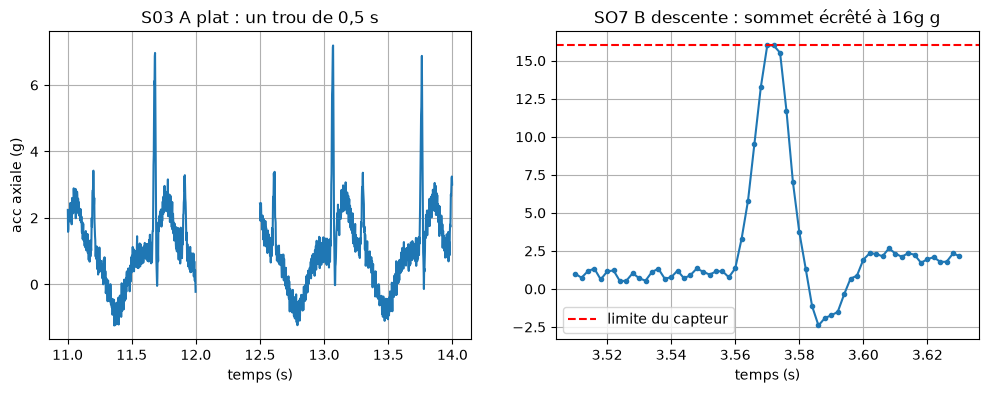

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))

d3 = pd.read_csv(IMU / "S03_chaussureA_plat.csv")
m = (d3.temps_s > 11) & (d3.temps_s < 14)
ax[0].plot(d3.temps_s[m], d3.acc_axial_g[m])
ax[0].set(title="S03 A plat : un trou de 0,5 s", xlabel="temps (s)", ylabel="acc axiale (g)")

d7 = pd.read_csv(IMU / "S07_chaussureB_descente.csv")
i = d7.acc_axial_g.idxmax()
z = d7.loc[i-30:i+30]
ax[1].plot(z.temps_s, z.acc_axial_g, ".-")
ax[1].axhline(16, color='r', ls='--', label="limite du capteur")
ax[1].set(title="SO7 B descente : sommet écrêté à 16g g", xlabel="temps (s)"); ax[1].legend()
plt.tight_layout
plt.show()


Partie 5 - Essai à la main, signal brut aux variables

In [ ]:
# Partie 5 : essaai à la main, du signal brut aux varibales
# Déroulement de chaque étape sur un essai propre pour comprendre puis rangement dans une fonction

df = pd.read_csv(IMU / "S01_chaussureA_plat.csv")

# Check list à faire avec tout nouveau fichier
print("Lignes :", len(df))
print("durée :", df.temps_s.iloc[-1], "s")
print("Fréquence estimée :", round(1 / df.temps_s.diff().median()), "Hz") # 1 / pas de temps 
print("Valeur manquantes:", df.isna().sum().sum())
df.head()



Lignes : 10000
durée : 19.998 s
Fréquence estimée : 500 Hz
Valeur manquantes: 0


,temps_s,acc_axial_g,acc_ap_g,gyr_ml_dps
0,0.000,0.750,0.204,-9.7
1,0.002,1.236,-0.051,-12.0
2,0.004,0.747,-0.135,5.5
3,0.006,1.003,0.010,0.4
4,0.008,0.980,0.208,8.5


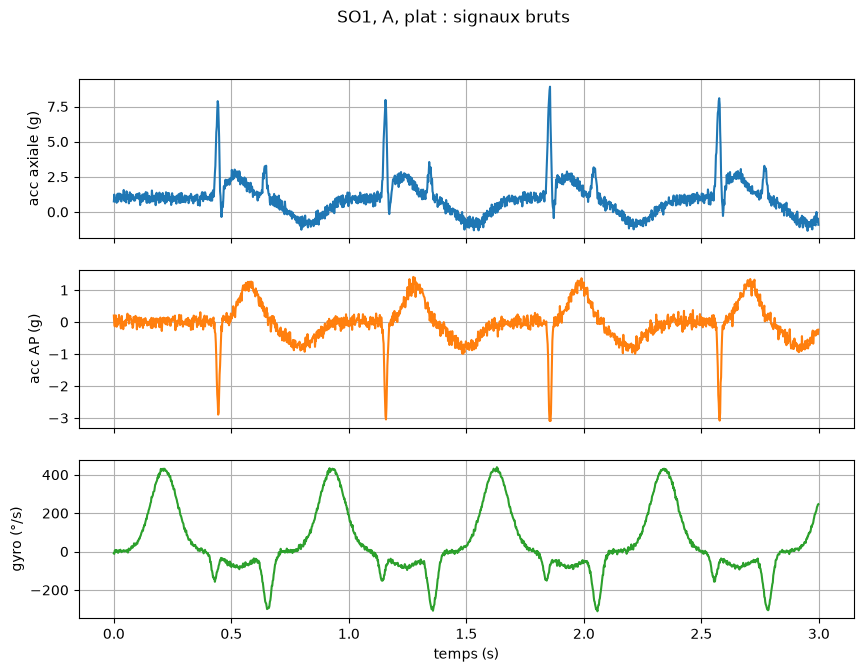

In [ ]:
m = df.temps_s < 3  # les 3 premières secondes 
fig, ax = plt.subplots(3,1, figsize=(10, 7), sharex=True) # 3 grpahes, même axe x
ax[0].plot(df.temps_s[m], df.acc_axial_g[m])
ax[0].set_ylabel("acc axiale (g)")

ax[1].plot(df.temps_s[m], df.acc_ap_g[m], color='C1')
ax[1].set_ylabel("acc AP (g)")

ax[2].plot(df.temps_s[m], df.gyr_ml_dps[m], color='C2')
ax[2].set_ylabel('gyro (°/s)')
ax[2].set_xlabel("temps (s)")
fig.suptitle("SO1, A, plat : signaux bruts")
plt.tight_layout
plt.show()


Explication des courbes : 
- accélération axiale : pic (6 - 9g) = impact du pied au sol ; ~0.25s plus tard = décollement
- Gyroscope = bosse positive (~400 °/s) = phase oscillante, 1 creux = contact ; deuxième creux = décollement

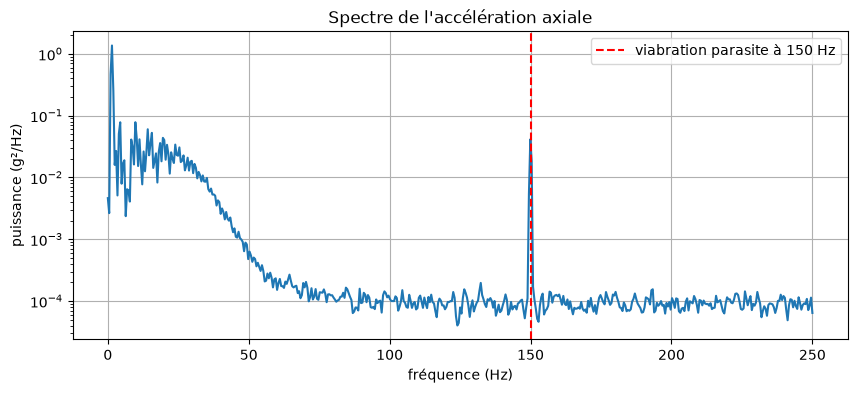

In [ ]:
# Filtrer 
# 1) regarder où est l'energie dans les fréquences(le spectre)
# 2) choisir une fréquence de coupure 
# 3) filtrer sans dephassage, poiurn ne pas décaler les pics dans le temps

acc_brut = df.acc_axial_g.to_numpy()    # colonne => tableau numpy (+ facile pour l'analyse) 

f, puissance = welch(acc_brut, fs=FS, nperseg=1024)   # spectre par la méthode de Welch
plt.semilogy(f, puissance)
plt.axvline(150, color='r', ls="--", label="viabration parasite à 150 Hz")
plt.xlabel("fréquence (Hz)")
plt.ylabel("puissance (g²/Hz)")
plt.legend()
plt.title("Spectre de l'accélération axiale")
plt.show()

# essentiel de l'énergie = sous 60hz, c'est le mouvement y compris l'impact 
# pic 150hz = vibration parasite 

# Filtre butterworth = standard biomécanique (filtfilt)
# La coupure depend de la variable : accélération tibiale (impact 10-20ms) => 50 - 100 Hz ; angles => 6-12Hz


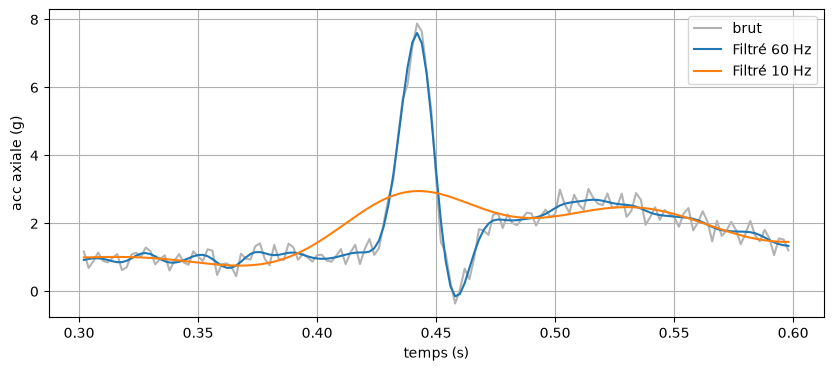

Pic : brut 7.88 g | 60 Hz 7.60 g | 10 Hz 2.95 g <- écrasé !


In [ ]:
def filtre_passe_bas(x, fc, fs=FS, ordre=4):
    ''' Butterworth passe-bas sans déphasage'''
    b, a = butter(ordre, fc / (fs / 2), btype="low") # coupure normalisée par Nyquist (fs/2)
    return filtfilt(b, a, x)

acc_60 = filtre_passe_bas(acc_brut, 60)
acc_10 = filtre_passe_bas(acc_brut, 10)       # trop bas, pour comparer

m = (df.temps_s > .3) & (df.temps_s < .6)
plt.plot(df.temps_s[m], acc_brut[m], color=".7", label="brut")
plt.plot(df.temps_s[m], acc_60[m], label="Filtré 60 Hz")
plt.plot(df.temps_s[m], acc_10[m], label="Filtré 10 Hz")
plt.xlabel("temps (s)")
plt.ylabel("acc axiale (g)")
plt.legend()
plt.show()
print(f"Pic : brut {acc_brut[m].max():.2f} g | 60 Hz {acc_60[m].max():.2f} g | 10 Hz {acc_10[m].max():.2f} g <- écrasé !")




    

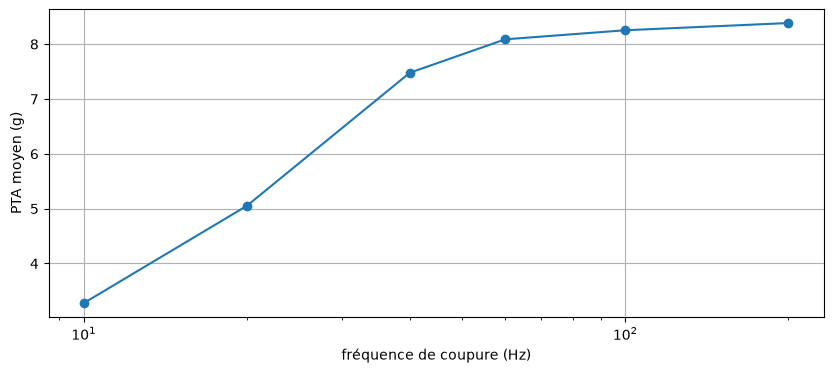

 fc  PTA
 10 3.28
 20 5.05
 40 7.48
 60 8.09
100 8.25
200 8.38


In [ ]:
fcs = [10, 20, 40, 60, 100, 200]
pta = []

for fc in fcs:
    acc_f = filtre_passe_bas(acc_brut, fc)
    pics, props = find_peaks(acc_f, height=3, distance=250)
    pta.append(props["peak_heights"].mean() if len(pics) else np.nan)

plt.plot(fcs, pta, "o-"); plt.xscale("log")
plt.xlabel("fréquence de coupure (Hz)"); plt.ylabel("PTA moyen (g)"); plt.show()
print(pd.DataFrame({"fc": fcs, "PTA": np.round(pta, 2)}).to_string(index=False))
# le PTA grimpe jsuq'a 40/50Hz puis se stablise : en dessous, le filtre mange l'impact
# au dessus de 100hz, on ajoute surtout du bruit, 60Hz est un choix assez justifié par ce graphique


In [ ]:
# Détection des foulées 

def detecter_foulees(acc, gyr, fs=FS, seuil=3.0, distance_s=.5, invalide=None):
    ''' Renvoi un tableau : une ligne par foulée, avec les indcies du contact, du pic et du décollement'''
    pics, _ = find_peaks(acc, height=seuil, distance=int(distance_s * fs))
    lignes = []

    for p in pics:
        debut = max(p - int(.040 * fs),0)    # fenêtre de 40ms avant le pic
        i_fs = debut + np.argmin(gyr[debut:p + 1])   # argmin = position du minimum
        a, b = i_fs + int(0.150 * fs), i_fs + int(0.400 * fs) # fenêtre du décollement
        if b >= len(gyr):                # foulée coupée par la fin du fichier 
            continue
        i_to = a + np.argmin(gyr[a:b])
        if invalide is not None and invalide[i_fs:i_to + 1].any():
            continue           # foulée dans un trou de donnée 
        lignes.append({"i_fs": i_fs, "i_pic":p, "i_to":i_to})
    return pd.DataFrame(lignes)

acc_f = filtre_passe_bas(acc_brut, CONFIG["fc_acc"])
gyr_f = filtre_passe_bas(df.gyr_ml_dps.to_numpy(), CONFIG["fc_gyr"])   # signal plus lent : 30 Hz suffit 
ev = detecter_foulees(acc_f, gyr_f)
print(len(ev), "foulées détectées")
ev.head()


28 foulées détectées


,i_fs,i_pic,i_to
0,215,221,327
1,571,578,678
2,920,927,1028
3,1278,1287,1391
4,1634,1641,1747


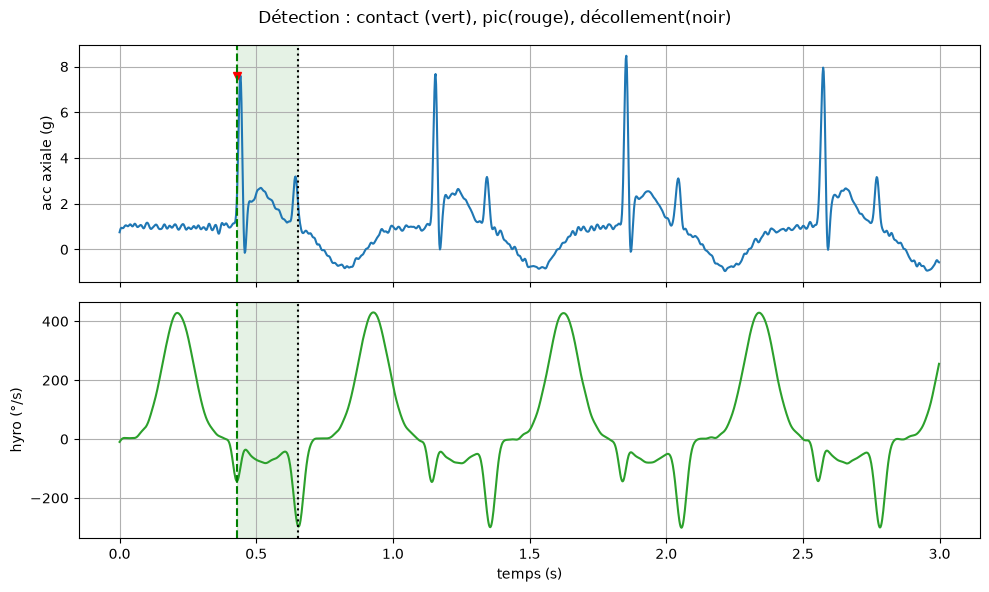

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [ ]:
# Visualisation pour vérifier la détection 
t = df.temps_s.to_numpy()
m = t < 3
fig, ax = plt.subplots(2,1, figsize=(10,6), sharex=True)
ax[0].plot(t[m], acc_f[m])
ax[1].plot(t[m], gyr_f[m], color='C2')

for e in ev[ev.i_to < m.sum()].itertuples():
    ax[0].plot(t[e.i_fs], acc_f[e.i_pic], "rv")

    for axe in ax:
        axe.axvspan(t[e.i_fs], t[e.i_to], color="g", alpha=0.1)  # zone verte : l'appui
        axe.axvline(t[e.i_fs], color="g", ls="--")               # contact 
        axe.axvline(t[e.i_to], color="k", ls=":")                # décollement

    ax[0].set_ylabel("acc axiale (g)")
    ax[1].set_ylabel("hyro (°/s)")
    ax[1].set_xlabel("temps (s)")

    fig.suptitle("Détection : contact (vert), pic(rouge), décollement(noir)")
    plt.tight_layout()
    plt.show()
    



In [ ]:
for h in [1.5, 3, 12]:
    pics, _ = find_peaks(acc_f, height=h, distance=250)
    print(f"height = {h:>4} g -> {len(pics)} pics")

# 1.5g = autant de pics (grâce à distance) mais risque de prendre la bosse de mi appuis
# 12g : aucun pic pour le coureur sur du plat. Un seuil fixe peut marcher en descente et écouher sur du plat
# Amélioration psosible : seuil RELATIF


height =  1.5 g -> 28 pics
height =    3 g -> 28 pics
height =   12 g -> 0 pics


In [ ]:
def calculer_variables(acc, ev, fs=FS):
    ev = ev.copy()
    ev["pta_g"] = acc[ev.i_pic]
    ev["temps_montee_ms"] = (ev.i_pic - ev.i_fs) / fs * 1000
    ev["taux_charge_gps"] = (acc[ev.i_pic] - acc[ev.i_fs]) / ((ev.i_pic - ev.i_fs) / fs)
    ev["temps_contact_ms"] = (ev.i_to - ev.i_fs) / fs * 1000
    ev["duree_foulee_s"] = ev.i_fs.diff() / fs                          # écart avec la foulée précédente
    ev.loc[ev.duree_foulee_s > 1.5 * ev.duree_foulee_s.median(), "duree_foulee_s"] = np.nan  # foulée manquée entre deux
    ev["cadence_ppm"] = 2 * 60 / ev.duree_foulee_s                      # 1 foulée = 2 pas
    return ev

def rejeter_aberrantes(ev, n_mad=3.0, colonnes=("pta_g", "temps_contact_ms")):
    garde = np.ones(len(ev), dtype=bool)
    for col in colonnes:
        x = ev[col]
        mad = 1.4826 * np.median(np.abs(x - x.median()))              # 1.4826 : MAD comparable à un écart-type
        if mad > 0:
            garde &= (np.abs(x - x.median()) <= n_mad * mad).values
    return ev[garde].reset_index(drop=True)

ev = calculer_variables(acc_f, ev)
ev_ok = rejeter_aberrantes(ev)
print(f"{len(ev)} foulées -> {len(ev_ok)} gardées")
ev_ok[["pta_g", "taux_charge_gps", "temps_contact_ms", "cadence_ppm"]].describe().round(1)

28 foulées -> 28 gardées


,pta_g,taux_charge_gps,temps_contact_ms,cadence_ppm
count,28.0,28.0,28.0,27.0
mean,8.1,431.5,225.5,169.6
std,0.6,59.9,8.2,2.7
min,6.3,328.1,206.0,164.4
25%,7.8,403.2,220.0,167.6
50%,8.1,425.3,226.0,169.5
75%,8.6,468.4,230.5,171.2
max,8.9,581.0,240.0,174.4


In [ ]:
for col in ["pta_g", "temps_contact_ms"]:
    print(f"CV {col:<17}: {ev_ok[col].std() / ev_ok[col].mean() * 100:.1f} %")

# PTA varien entre 7% et temps contact 3%, plus une varible varie = plus il faut de foules pour une moyenne stable
# On vise entre 15 et 30 foulées par condition
    

CV pta_g            : 7.7 %
CV temps_contact_ms : 3.6 %


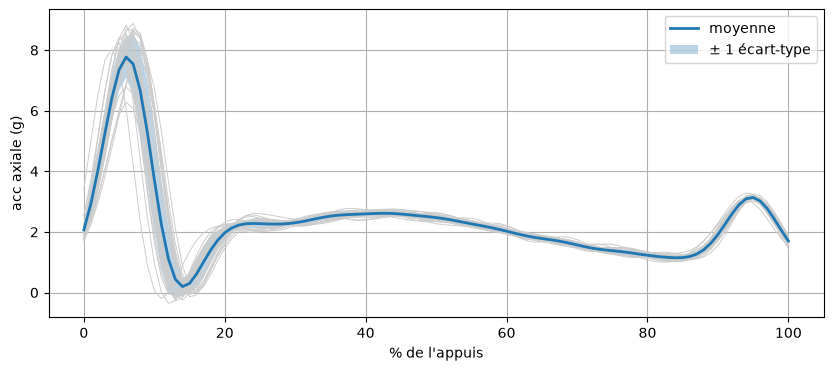

In [ ]:
# Normaliser dans le temps => 0 à 100%de l'appui

def normaliser_appuis(acc, ev, n=101):
    x_new = np.linspace(0,1,n)
    courbes = [np.interp(x_new, np.linspace(0,1, e.i_to - e.i_fs + 1), acc[e.i_fs:e.i_to + 1])
               for e in ev.itertuples()]       # chaque appuis => 101 points (0 à 100)
    return np.array(courbes)                   # tableau (n_foules x 101)

courbes = normaliser_appuis(acc_f, ev_ok)
moy, et = courbes.mean(0), courbes.std(0)
plt.plot(courbes.T, color=".8", lw=.7)
plt.plot(moy, lw=2, label="moyenne")
plt.fill_between(range(101), moy - et, moy + et, alpha=.3, label="± 1 écart-type")
plt.xlabel("% de l'appuis")
plt.ylabel("acc axiale (g)")
plt.legend()
plt.show()




In [ ]:
# Partie 6 : rangement en fonction => analyser les 40 essais

def remplir_trous(x, fs, trou_max_s):
    ''' interpole tous les Nan, mais marque comme "ivalides" les trous trop longs '''
    x = np.asarray(x, float).copy()
    nan = np.isnan(x)
    invalide = np.zeros(len(x), dtype=bool)
    if nan.any():
        bords = np.diff(np.concatenate([[0], nan.astype(int), [0]]))

        for debut, fin in zip(np.where(bords == 1)[0], np.where(bords == -1)[0]):
            if (fin - debut) / fs > trou_max_s:
                invalide[debut:fin] = True
        idx = np.arange(len(x))
        x[nan] = np.interp(idx[nan], idx[~nan], x[~nan])
    return x, invalide


def analyser_essai(chemin, cfg=CONFIG):
    ''' Tout le traitement d'un essai, Renvoi (foulées, courbes, qualité).'''
    df = pd.read_csv(chemin)
    acc_brut = df.acc_axial_g.to_numpy()
    acc, inv_a = remplir_trous(acc_brut, cfg["fc_acc"], cfg["trou_max_s"])
    gyr, inv_g = remplir_trous(df.gyr_ml_dps.to_numpy(), cfg["fs"], cfg["trou_max_s"])
    
    acc = filtre_passe_bas(acc, cfg["fc_acc"], cfg["fs"])
    gyr = filtre_passe_bas(gyr, cfg["fc_gyr"], cfg["fs"])
    
    ev = detecter_foulees(acc, gyr, cfg["fs"], cfg["seuil_pic_g"], cfg["distance_pics_s"], inv_a | inv_g)
    ev = calculer_variables(acc, ev, cfg["fs"])
    ok = rejeter_aberrantes(ev, cfg["n_mad"])

    n_sat = int((np.abs(acc_brut[~np.isnan(acc_brut)]) >= cfg["etendue_g"] - 0.01).sum())
    qualite = {"n_detectees": len(ev), "n_gardees": len(ok), "n_satures":n_sat}
    return ok, normaliser_appuis(acc,ok), qualite

# On vérifie qu'elle donne bien le résultat obtenue pour la 1ère personne
ok, _, q = analyser_essai(IMU / "S01_chaussureA_plat.csv")
print("À la main : PTA =", round(ev_ok.pta_g.mean(), 3), "| fonction :", round(ok.pta_g.mean(), 3), "|", q)



À la main : PTA = 8.087 | fonction : 8.087 | {'n_detectees': 28, 'n_gardees': 28, 'n_satures': 0}


In [ ]:
# On fait la même chose pour toutes les données 

toutes = []
qualite = []
COURBES = {}

for f in sorted(IMU.glob("*.csv")):
    m = re.match(MOTIF, f.name)                    # on retrouve coureur, chaussure, pente dans le nom
    if m is None:
        continue
    info = m.groupdict()
    foulees, courbes, q = analyser_essai(f)
    for k, v in info.items():
        foulees[k] = v                             # on ajoute les conditions à chaque foulée
    toutes.append(foulees)
    qualite.append({**info, **q})
    COURBES[(info["coureur"], info["chaussure"], info["pente"])] = courbes

FOULEES = pd.concat(toutes, ignore_index=True)     # 1 ligne = 1 foulée
QUALITE = pd.DataFrame(qualite)                    # 1 ligne = 1 essai

# Les essais saturés : PTA et taux de charge faux -> on les met à NaN (valeur manquante)
for r in QUALITE[QUALITE.n_satures > 0].itertuples():
    sel = (FOULEES.coureur == r.coureur) & (FOULEES.chaussure == r.chaussure) & (FOULEES.pente == r.pente)
    FOULEES.loc[sel, ["pta_g", "taux_charge_gps"]] = np.nan

VARIABLES = ["pta_g", "taux_charge_gps", "temps_contact_ms", "cadence_ppm"]
ESSAIS = FOULEES.groupby(["coureur", "chaussure", "pente"])[VARIABLES].mean().reset_index()   # 1 ligne = 1 essai
print(len(FOULEES), "foulées,", len(ESSAIS), "essais")
QUALITE.sort_values("n_gardees").head()






1087 foulées, 39 essais


,coureur,chaussure,pente,n_detectees,n_gardees,n_satures
5,S02,A,plat,27,21,0
33,S09,A,plat,26,25,0
7,S02,B,plat,27,25,0
35,S09,B,plat,26,26,0
34,S09,B,descente,27,26,0


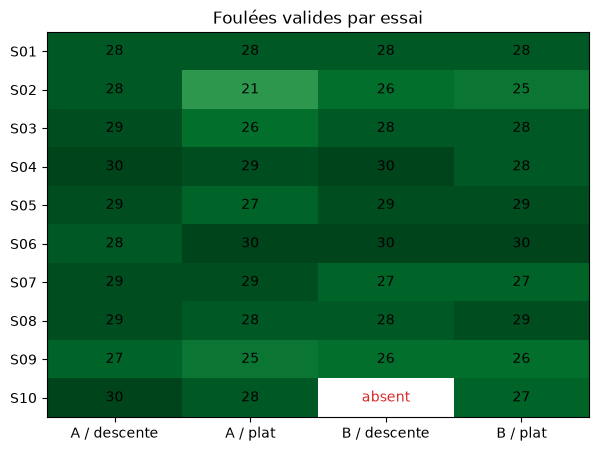

In [ ]:
# Carte de qualité : nombre de foulées gardées par essai
grille = QUALITE.assign(condition=QUALITE.chaussure + " / " + QUALITE.pente) \
                .pivot_table(index="coureur", columns="condition", values="n_gardees")

fig, ax = plt.subplots(figsize=(7, 5))

ax.imshow(grille.values, cmap="Greens", aspect="auto", vmin=0); ax.grid(False)
ax.set_xticks(range(grille.shape[1]), grille.columns); ax.set_yticks(range(grille.shape[0]), grille.index)

for i in range(grille.shape[0]):
    for j in range(grille.shape[1]):
        v = grille.values[i, j]
        ax.text(j, i, "absent" if np.isnan(v) else int(v), ha="center", va="center", color="C3" if np.isnan(v) else "k")
ax.set_title("Foulées valides par essai"); plt.show()


In [ ]:
# Partie 7 : Statisitiques

ESSAIS.groupby(["pente", "chaussure"])[VARIABLES].agg(["mean", "std"]).round(1)







pta_g      taux_charge_gps        temps_contact_ms        \
                    mean  std            mean    std             mean   std   
pente    chaussure                                                            
descente A           8.9  2.2           571.9  170.2            251.8  21.9   
         B           9.3  2.1           674.8  172.9            241.7  20.8   
plat     A           6.9  1.5           367.4   92.2            271.1  22.0   
         B           7.5  1.5           491.0  116.8            264.8  22.0   

                   cadence_ppm       
                          mean  std  
pente    chaussure                   
descente A               179.3  7.4  
         B               179.8  7.7  
plat     A               174.6  7.8  
         B               175.3  7.5

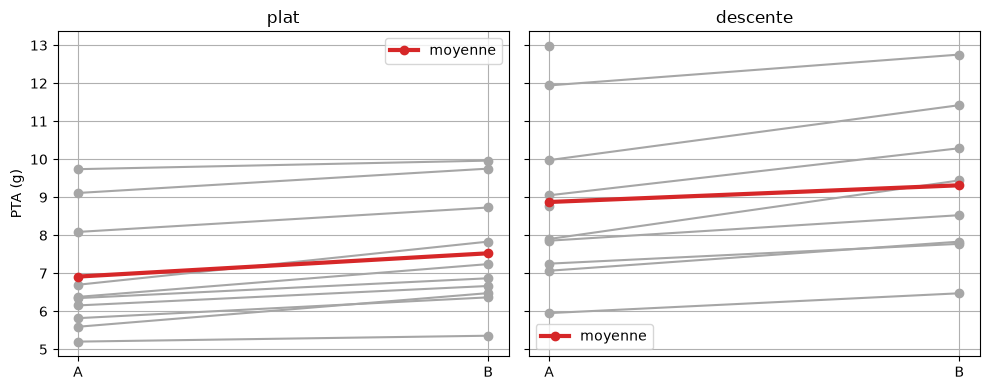

In [ ]:
# graphique "spahhetti" : une ligne par coureur. On voit si tous vont dans le même sens

fig, ax = plt.subplots(1, 2, figsize=(10,4), sharey=True)
for k, pente in enumerate(["plat", "descente"]):
    large = ESSAIS[ESSAIS.pente == pente].pivot(index="coureur", columns="chaussure", values="pta_g")

    for _, ligne in large.iterrows():
        ax[k].plot([0,1], ligne.values, "o-", color="0.65")
    ax[k].plot([0, 1], large.mean().values, "o-", color="C3", lw=3, label="moyenne")
    ax[k].set_xticks([0, 1], ["A", "B"])
    ax[k].set_title(pente)
    ax[k].legend()
ax[0].set_ylabel("PTA (g)")
plt.tight_layout()
plt.show()




In [ ]:
# Comparaison appariée et taille d'effet 
# Utilisation p-value => signifactif ou pas 
# taille d'effet, en appartié => dz = moyenne des différences / écart-type des différence 
# 0.2 = petit / 0.5 = moyen / 0.8 = grand

def comparer(essais, variable, pente):
    large = essais[essais.pente == pente].pivot(index="coureur", columns="chaussure", values=variable).dropna()
    diff = large["B"] - large["A"]
    t, p = sps.ttest_rel(large["B"], large["A"])

    return {"variable": variable, "pente": pente, "n": len(diff),
            "diff": diff.mean(), "diff_%": ((large.B / large.A).mean() - 1) * 100,
            "dz": diff.mean() / diff.std(ddof=1), "p": p,
            "n_dans_le_sens": int((np.sign(diff) == np.sign(diff.mean())).sum())}

pd.DataFrame([comparer(ESSAIS, v, pe) for pe in ["plat", "descente"] for v in VARIABLES]).round(3)

    

,variable,pente,n,diff,diff_%,dz,p,n_dans_le_sens
0,pta_g,plat,10,0.613,9.251,2.063,0.000,10
1,taux_charge_gps,plat,10,123.587,33.951,4.058,0.000,10
2,temps_contact_ms,plat,10,-6.307,-2.340,-2.851,0.000,10
3,cadence_ppm,plat,10,0.729,0.426,0.940,0.016,8
4,pta_g,descente,8,0.940,11.226,2.292,0.000,8
5,taux_charge_gps,descente,8,144.043,27.459,3.560,0.000,8
6,temps_contact_ms,descente,9,-6.429,-2.638,-2.678,0.000,9
7,cadence_ppm,descente,9,1.294,0.721,3.164,0.000,9


In [ ]:
# Combien de coureurs faudra-t-il pour la prochaine étude ? (puissance de 80%)

for dz in [0.3, 0.5, 0.8]:
    print(f"effet dz = {dz} -> {int(np.ceil(TTestPower().solve_power(effect_size=dz, alpha=0.05, power=0.8)))} coureurs")
    


effet dz = 0.3 -> 90 coureurs
effet dz = 0.5 -> 34 coureurs
effet dz = 0.8 -> 15 coureurs


In [ ]:
# Le modèle linéaire mixte
# Utilisation de toutes les foulées:

# PTA = β0 + β1 chaussure + β2pente + β3 chaussure x pente + ucoureur + ε

donnees = FOULEES.dropna(subset=["pta_g"])
modele = smf.mixedlm("pta_g ~ C(chaussure) * C(pente, Treatment('plat'))", data=donnes, groups=donnees["coureur"]).fit()

modele.summary().tables[1]


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,6.903,0.585,11.801,0.000,5.757,8.050
C(chaussure)[T.B],0.619,0.066,9.341,0.000,0.489,0.749
"C(pente, Treatment('plat'))[T.descente]",1.977,0.066,30.061,0.000,1.848,2.106
"C(chaussure)[T.B]:C(pente, Treatment('plat'))[T.descente]",0.158,0.097,1.640,0.101,-0.031,0.348
Group Var,3.400,2.077,,,,


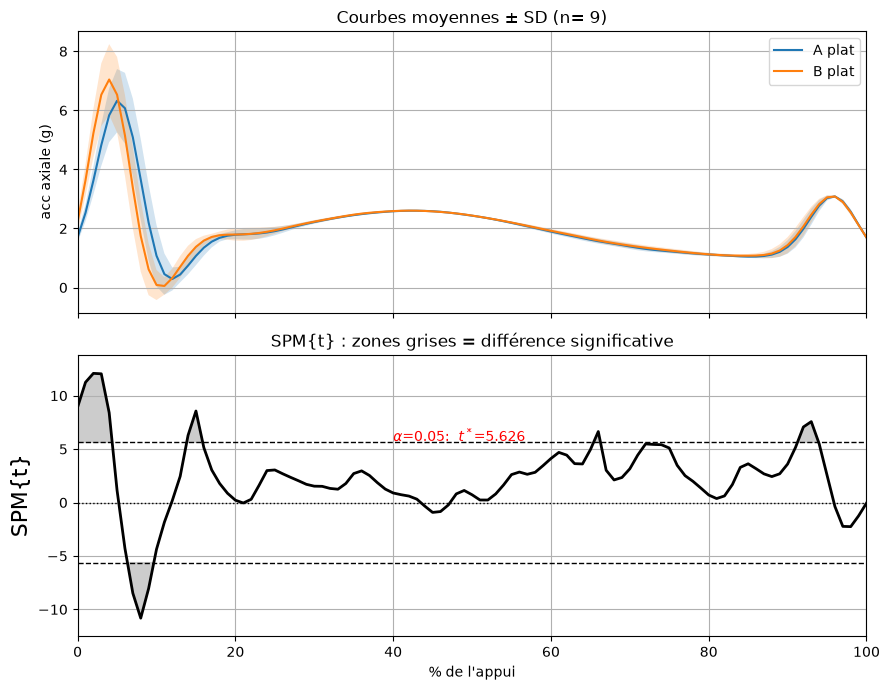

In [ ]:
# SPM => test chaque instant de l'appui en corrigeant pour les comparaisons multiples
import spm1d

satures = set(QUALITE.loc[QUALITE.n_satures > 0, "coureur"])
sujets = [s for s in sorted(ESSAIS.coureur.unique())
          if s not in satures and (s, "A", "plat") in COURBES and (s, "B", "plat") in COURBES]

YA = np.array([COURBES[(s, "A", "plat")].mean(0) for s in sujets])    # 1 courbe moyenne par coureur
YB = np.array([COURBES[(s, "B", "plat")].mean(0) for s in sujets])
ti = spm1d.stats.ttest_paired(YB, YA).inference(alpha=0.05, two_tailed=True)

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for Y, lab in [(YA, "A plat"), (YB, "B plat")]:
    ax[0].plot(Y.mean(0), label=lab)
    ax[0].fill_between(range(101), Y.mean(0) - Y.std(0), Y.mean(0) + Y.std(0), alpha=0.2)
ax[0].set_ylabel("acc axiale (g)")
ax[0].legend()
ax[0].set_title(f"Courbes moyennes ± SD (n= {len(sujets)})")

plt.sca(ax[1])
ti.plot()
ti.plot_threshold_label()

ax[1].set_xlabel("% de l'appui")
ax[1].set_title("SPM{t} : zones grises = différence significative")
plt.tight_layout()
plt.show()



In [ ]:
m_ct = smf.mixedlm("temps_contact_ms ~ C(chaussure) * C(pente, Treatment('plat'))",
                   data=FOULEES, groups=FOULEES["coureur"]).fit()
print(m_ct.summary().tables[1])

# Plus court en descente (~19ms) et un peu avec B(~ -7ms). Interaction non significative

                       

                                                      Coef. Std.Err.        z  \
Intercept                                           271.111    6.994   38.763   
C(chaussure)[T.B]                                    -6.319    0.653   -9.672   
C(pente, Treatment('plat'))[T.descente]             -19.356    0.648  -29.879   
C(chaussure)[T.B]:C(pente, Treatment('plat'))[T...   -0.078    0.933   -0.084   
Group Var                                           487.008   30.128            

                                                    P>|z|   [0.025   0.975]  
Intercept                                           0.000  257.403  284.819  
C(chaussure)[T.B]                                   0.000   -7.599   -5.038  
C(pente, Treatment('plat'))[T.descente]             0.000  -20.625  -18.086  
C(chaussure)[T.B]:C(pente, Treatment('plat'))[T...  0.933   -1.906    1.750  
Group Var                                                                    


In [ ]:
# Partie 8 : perception des coureurs 

perception = pd.read_csv(CONFIG["dossier"] / "perception.csv")
for col in ["confort", "amorti_percu", "stabilite"]:
            perception.loc[(perception[col] < 0) | (perception[col] > 100), col] = np.nan   # le "150" devient mauquant

fusion = ESSAIS.merge(perception, on=["coureur", "chaussure", "pente"])

def correlation_intra(d, x, y, sujet="coureur"):
    d = d[[sujet, x, y]].dropna()
    xc = d[x] - d.groupby(sujet)[x].transform("mean")    # on retire à chaque fois sa moyenne
    yc = d[y] - d.groupby(sujet)[y].transform("mean")
    return {"echelle": y, "r_brut": sps.pearsonr(d[x], d[y])[0], "r_intra": np.corrcoef(xc, yc)[0, 1]}

pd.DataFrame([correlation_intra(fusion, "pta_g", e) for e in ["confort", "amorti_percu", "stabilite"]]).round(2)


,echelle,r_brut,r_intra
0,confort,-0.26,-0.56
1,amorti_percu,-0.30,-0.82
2,stabilite,0.00,0.08


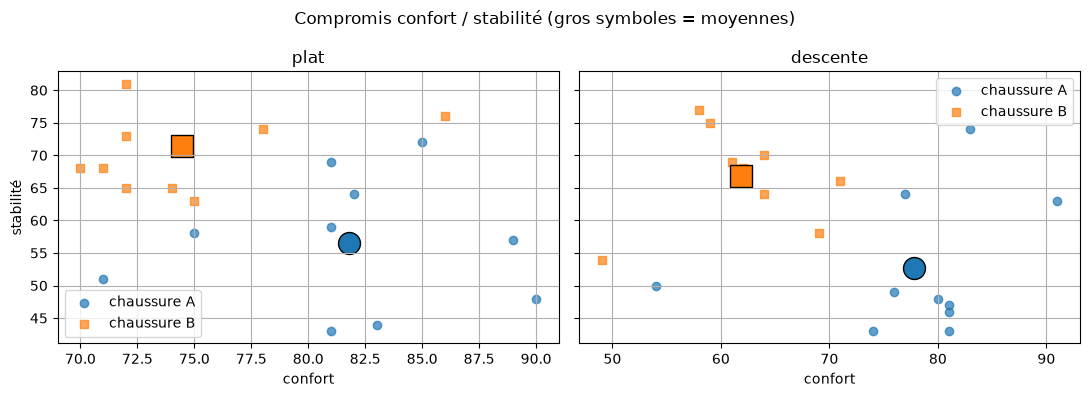

In [ ]:
# Compromis produit : B est moins confortable mais nettement plus stable

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for k, pente in enumerate(["plat", "descente"]):
    for j, (ch, mk) in enumerate([("A", "o"), ("B", "s")]):
        s = perception[(perception.pente == pente) & (perception.chaussure == ch)]
        ax[k].scatter(s.confort, s.stabilite, marker=mk, alpha=0.7, label=f"chaussure {ch}")
        ax[k].scatter(s.confort.mean(), s.stabilite.mean(), marker=mk, s=250, ec="k", color=f"C{j}")
    ax[k].set(title=pente, xlabel="confort"); ax[k].legend()
ax[0].set_ylabel("stabilité"); plt.suptitle("Compromis confort / stabilité (gros symboles = moyennes)")
plt.tight_layout(); plt.show()





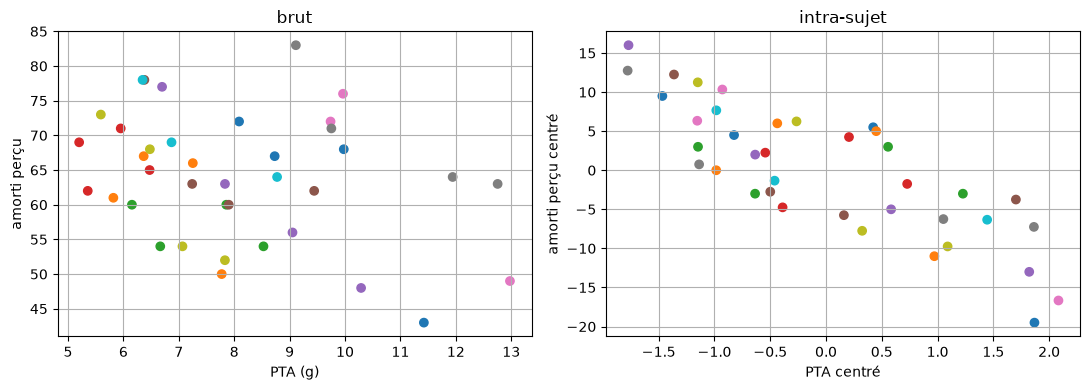

In [ ]:
# Amorti percu en fonction du PTA

d = fusion.dropna(subset=["pta_g", "amorti_percu"]).copy()

for col in ["pta_g", "amorti_percu"]:
    d[col + "_c"] = d[col] - d.groupby("coureur")[col].transform("mean")

couleur = pd.factorize(d.coureur)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(d.pta_g, d.amorti_percu, c=couleur, cmap="tab10")
ax[0].set(xlabel="PTA (g)", ylabel="amorti perçu", title="brut")

ax[1].scatter(d.pta_g_c, d.amorti_percu_c, c=couleur, cmap="tab10")
ax[1].set(xlabel="PTA centré", ylabel="amorti perçu centré", title="intra-sujet")
plt.tight_layout()
plt.show()

# Plus d'impact = moins d'amorti percu


In [ ]:
# Partie 9 : Vérifier le pipeline contre vérité 

vrai = pd.Series(json.loads((CONFIG["dossier"] / "verite.json").read_text())["reponse_B"], name="vrai")
plat = ESSAIS[ESSAIS.pente == "plat"].pivot(index="coureur", columns="chaussure", values="pta_g")
tab = pd.concat([vrai, (plat.B / plat.A).rename("mesuré")], axis=1).round(3)

print(tab)
communs = tab.dropna()                          # on compare sur les mêmes coureurs des deux côtés
print(f"\nEffet moyen de B : vrai +{(communs.vrai.mean() - 1) * 100:.1f} % | mesuré +{(communs['mesuré'].mean() - 1) * 100:.1f} %")





      vrai  mesuré
S01  1.123   1.079
S02  1.094   1.094
S03  1.074   1.083
S04  1.072   1.030
S05  1.150   1.169
S06  1.179   1.135
S07  1.083   1.023
S08  1.095   1.070
S09  1.130   1.158
S10  1.121   1.082

Effet moyen de B : vrai +11.2 % | mesuré +9.2 %


In [ ]:
# Analyse de sensibilité 
sans_S07 = [s for s in communs.index]
for fc in [40, 60, 100, 150]:
    CONFIG["fc_acc"] = fc
    r = [analyser_essai(IMU / f"{s}_chaussureB_plat.csv")[0].pta_g.mean() / 
         analyser_essai(IMU / f"{s}_chaussureA_plat.csv")[0].pta_g.mean() for s in sans_S07]

    print(f"fc = {fc:>3} Hz : mesuré + {(np.mean(r) - 1) * 100:.1f} % (vrai+{(vrai[sans_S07].mean() - 1) * 100:.1f} %)")

    CONFIG["fc_acc"] = 60

# Plus fc est haute => + s'approche de la vérité
# Conclusion B augmente le PTA = ROBUSTE

fc =  40 Hz : mesuré + 5.3 % (vrai+11.2 %)
fc =  60 Hz : mesuré + 9.3 % (vrai+11.2 %)
fc = 100 Hz : mesuré + 10.6 % (vrai+11.2 %)
fc = 150 Hz : mesuré + 10.4 % (vrai+11.2 %)


In [ ]:
# Partie 10 : création code Test

# On vérifie 3 choses : 
# - Proprétés physiques : filtre garde basses fréquences, supprimes haute, pas de décallage des pics
# - Vérité => sur un essai simulé, contact ~ 10ms
# - Contrôle de données : si fichier abimé => détection

def test_filtre_garde_les_basses_frequences():
    t = np.arange(0, 4, 1 / FS)
    y = filtre_passe_bas(np.sin(2 * np.pi * 5 * t), 60)
    assert abs(y[FS:-FS].max() - 1) < 0.02                  # une sinusoïde à 5 Hz garde son amplitude

def test_filtre_supprime_150_hz():
    t = np.arange(0, 4, 1 / FS)
    y = filtre_passe_bas(np.sin(2 * np.pi * 150 * t), 60)
    assert np.abs(y[FS:-FS]).max() < 0.01                   # une sinusoïde à 150 Hz disparaît

def test_filtre_ne_decale_pas_les_pics():
    t = np.arange(0, 4, 1 / FS)
    x = np.exp(-0.5 * ((t - 2) / 0.02) ** 2)                # un pic à 2 s
    assert abs(np.argmax(filtre_passe_bas(x, 30)) - np.argmax(x)) <= 1

def test_contact_detecte_a_moins_de_10_ms():
    df_t, verite = simuler_essai(8.0, 0.25, 170, 0.018, np.random.default_rng(42))
    acc = filtre_passe_bas(df_t.acc_axial_g.to_numpy(), 60)
    gyr = filtre_passe_bas(df_t.gyr_ml_dps.to_numpy(), 30)
    ev_t = detecter_foulees(acc, gyr)
    vrais = np.array(verite["t_fs"])
    for i in ev_t.i_fs:
        assert np.min(np.abs(vrais - i / FS)) < 0.010

def test_normalisation_101_points():
    ev_t = pd.DataFrame({"i_fs": [0], "i_pic": [5], "i_to": [136]})
    c = normaliser_appuis(np.linspace(2, 7, 200), ev_t)
    assert c.shape == (1, 101) and c[0, 0] == 2

tests = [test_filtre_garde_les_basses_frequences, test_filtre_supprime_150_hz,
         test_filtre_ne_decale_pas_les_pics, test_contact_detecte_a_moins_de_10_ms, test_normalisation_101_points]
for test in tests:
    test()                                                  # s'il y a un problème, une erreur s'affiche ici
    print("OK   ", test.__name__)


OK    test_filtre_garde_les_basses_frequences
OK    test_filtre_supprime_150_hz
OK    test_filtre_ne_decale_pas_les_pics
OK    test_contact_detecte_a_moins_de_10_ms
OK    test_normalisation_101_points


In [ ]:
import shutil, tempfile

def test_unites_m_s2_detectees():
    copie = Path(tempfile.mkdtemp()) / "etude"
    shutil.copytree(CONFIG["dossier"], copie)
    f = copie / "imu" / "S01_chaussureA_plat.csv"
    d = pd.read_csv(f)

    d["acc_axial_g"] *= 9.81       # comme si le fichier était en m/s²
    d.to_csv(f, index=False)
    resultat = controler_etude({**CONFIG, "dossier": copie})
    assert resultat.message.str.contains("m/s²").any()

test_unites_m_s2_detectees()
print("OK      test_unites_m_s2_detectees")
    

OK      test_unites_m_s2_detectees
